In [1]:
from pathlib import Path
import pandas as pd
import nibabel as nib
from jinja2.sandbox import safe_range
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score
import numpy as np
import pickle
import random
import SimpleITK as sitk
import cv2
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
import numpy as np
from torchvision import transforms
import mysql.connector
import os
from PIL import ImageOps
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import vtk
from scipy.spatial.transform import Rotation as R
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt
from pytorch3d.ops import sample_farthest_points


In [2]:
res_size = (96, 48, 128)

base_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")
skull_file = base_folder / "combined_skull_analysis.xlsx"

images_folder = r"/home/varhai/PRIMUS/var_vestlontest/export/images/"
conn = mysql.connector.connect(option_files=os.path.expanduser('~/.my.cnf')) 
sql_query = """
SELECT o.SPECIMEN_ID,s.STRAIN,s.GENDER, m.COHORT_ID, e.DATE,o.VALUE_CATEGORY as SkullShape, LEN.VALUE_DATA_POINT as CraniumLength,COM.VALUE_TEXT as Comment
FROM OBSERVATION as o
    INNER JOIN MOUSE as m ON o.SPECIMEN_ID = m.ID
    INNER JOIN SPECIMEN as s ON m.ID = s.ID
    INNER JOIN EXPERIMENT as e ON e.ID = o.EXPERIMENT_ID
    INNER JOIN PARAMETER as p ON o.PARAMETER_STABLE_ID = p.PARAMETER_STABLE_ID
    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_TEXT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_032_001'
    ) AS COM ON o.SPECIMEN_ID = COM.SPECIMEN_ID

    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_DATA_POINT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_893_001'
    ) AS LEN ON o.SPECIMEN_ID = LEN.SPECIMEN_ID
WHERE
    m.COHORT_ID LIKE 'c%'
    AND o.PARAMETER_STABLE_ID = 'CCP_XRY_001_001';
"""
# Reading data into a Pandas DataFrame
db_df_test = pd.read_sql(sql_query, conn)
skull_df = pd.read_excel(skull_file)

/tmp/ipykernel_2304985/3376971098.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  db_df_test = pd.read_sql(sql_query, conn)


In [3]:
# match sutures with database
# Defining your SQL query


sql_query = """
SELECT SPECIMEN_ID, VALUE_IMAGE_URI FROM `OBSERVATION` WHERE `PARAMETER_STABLE_ID` = 'CCP_XRY_051_001' AND `INCREMENT_VALUE` = '001'
 and VALUE_IMAGE_URI is not null 
"""
# Reading data into a Pandas DataFrame
db_df = pd.read_sql(sql_query, conn)

# Closing the connection
conn.close()
display(db_df)

/tmp/ipykernel_2304985/1025891440.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  db_df = pd.read_sql(sql_query, conn)


,SPECIMEN_ID,VALUE_IMAGE_URI
0,064-EPJ77,2018-07-11/nub1_f_83z-epj77_cr1.bmp
1,064-EPJ81,2018-07-11/nub1_m_064-epj81_cr1.bmp
2,064-EPJ82,2018-07-11/nub1_m_064-epj82_cr1.bmp
3,064-EPJ85,2018-07-11/nub1_f_83z-epj85_cr1.bmp
4,064-EPJ86,2018-07-11/nub1_f_83z-epj86_cr1.bmp
...,...,...
10888,E83-F2740,2020-08-24/fam161b_m_e83-f2740_cr1.bmp
10889,E83-F2743,2020-08-24/fam161b_f_e83-f2743_cr1.bmp
10890,E83-F2749,2021-01-22/fam161b_f_e83-f2749_cr1.bmp
10891,E83-F2750,2021-01-22/fam161b_f_e83-f2750_cr1.bmp


# Filter subjects with skull data which have sutures

In [4]:
# merge the dataframes
skull_df["Specimen_ID"] = skull_df["Unnamed: 0"].apply(lambda x: x.split("_")[-1])
skull_df = skull_df.merge(db_df, left_on="Specimen_ID", right_on="SPECIMEN_ID")


skull_df = skull_df[skull_df['proc_dist']<3000]


In [5]:
# get 2 classes for sutures (equal number of sutures and no sutures)

#no_sutures_df = no_sutures_df.sample(n=sutures_df.shape[0], random_state=42)

In [6]:
# generate train and test split take equal number of sutures and no sutures for each
train_df = skull_df.sample(frac=0.8, random_state=42)
test_df = skull_df.drop(train_df.index)
# randomize the dataset
train_df = train_df.sample(frac=1, random_state=42)
test_df = test_df.sample(frac=1, random_state=42)

In [7]:
test_df.describe()

,DATE,CraniumLength,proc_dist,area99perc,s_x,s_y,s_z
count,789,770.000000,789.000000,789.000000,789.000000,789.000000,789.000000
mean,2022-06-14 07:43:34.448669184,26.361991,742.647587,0.059963,1.028549,0.992273,0.958969
min,2020-09-28 00:00:00,21.550000,218.461700,0.000000,0.879162,0.831809,0.621642
25%,2021-09-20 00:00:00,26.020000,463.334501,0.000884,1.006299,0.979774,0.952195
50%,2022-06-13 00:00:00,26.400000,577.782632,0.005803,1.022000,0.993386,0.965572
75%,2023-02-27 00:00:00,26.780000,773.474272,0.021790,1.038710,1.006319,0.979331
max,2023-11-20 00:00:00,28.390000,2989.457342,0.999693,2.120344,1.578354,1.383324
std,NaN,0.677592,506.679115,0.187133,0.054225,0.032137,0.045388


In [ ]:
from typing import Tuple
import numpy as np
import nibabel as nib
import vtk
from scipy.spatial.transform import Rotation as R
import cv2
from tqdm import tqdm
import os
from PIL import ImageOps
import torch
import torchvision.transforms as transforms

from sys import getsizeof

def flip_image(im_file_in: str, im_file_out: str, axis:Tuple[int,int,int]):
    # Load your image (replace 'image_path' with the path to your image)
    image = sitk.ReadImage(im_file_in)
    # Flip the image along a specific axis (e.g., along the x-axis)
    # Flip the image along the x-axis
    #flipped_image = sitk.Flip(image, [True, False, False])  # [X, Y, Z] axis flipping
    # Specify the axis along which you want to mirror (0 for x-axis, 1 for y-axis, 2 for z-axis)
    axis_to_mirror = 0  # For example, mirror along the x-axis
    image_array = sitk.GetArrayFromImage(image)
    # Flip the image along the specified axis
    mirrored_image_array = np.flip(image_array, axis=axis#'(1,2)
    )

    # Create a SimpleITK image from the mirrored NumPy array
    flipped_image = sitk.GetImageFromArray(mirrored_image_array)

    # Set the origin, spacing, and direction cosine matrix if needed
    flipped_image.SetOrigin(image.GetOrigin())
    flipped_image.SetSpacing(image.GetSpacing())
    flipped_image.SetDirection(image.GetDirection())

    # Apply the flipping transformation to the image

    sitk.WriteImage(flipped_image, im_file_out)


def get_head_file_n_mesh(subj_id, cohort_id):
    """
    Get the head file and mesh file for a given subject and cohort
    :param subj_id: 
    :param cohort_id: 
    :return: 
    """
    folders = [x for x in base_folder.iterdir() if cohort_id in x.name and (x/"skull_shape_workdir").exists()]
    for fold in folders:
        files = list((fold/"skull_shape_workdir").iterdir())
        for file in files:
            if str(subj_id) in file.name:
                if (file/"head_affine_registered.obj").exists() and (file/"oriented_image.nii.gz").exists()\
                        and (file/"affine_head.mat").exists():
                    filenames_ = ["coreg_1.mat", "coreg_2.mat", "coreg_3.mat","coreg_or.mat"]
                    # check which files not exist from filenames_
                    exist_files = {x: (file/x).exists() for x in filenames_}
                    # check that exist exactly 3 files
                    if sum(exist_files.values()) == 3:
                        # check which file not exist
                        not_exist_file = [x for x in filenames_ if not exist_files[x]][0]
                        if (file/"ct_image_.nii.gz").exists():
                            ctim = str(file/"ct_image_.nii.gz")
                        elif (file/"ct_image.nii.gz").exists():
                            ctim = str(file/"ct_image.nii.gz")
                        #flip_image(ctim, str(file / "preregister_image1.nii.gz"),axis=(1,2))
                        #flip_image(ctim, str(file / "preregister_image2.nii.gz"),axis=(0,2))
                        #flip_image(ctim, str(file / "preregister_image3.nii.gz"),axis=(0,1))
                        if not (file / "preregister_image.nii.gz").exists():

                            if not_exist_file == "coreg_1.mat":
                                flip_image(ctim, str(file / "preregister_image.nii.gz"),axis=(1,2))
                            elif not_exist_file == "coreg_2.mat":
                                flip_image(ctim, str(file / "preregister_image.nii.gz"),axis=(0,2))
                            elif not_exist_file == "coreg_3.mat":
                                flip_image(ctim, str(file / "preregister_image.nii.gz"),axis=(0,1))
                            elif not_exist_file == "coreg_or.mat":
                                # copy ct_image to preregister_image
                                os.system(f"cp {ctim} {str(file/'preregister_image.nii.gz')}")
                        if not (file/"preregister_mask.nii.gz").exists():        
                            otsu_treshold((file / "preregister_image.nii.gz"), (file / "preregister_mask.nii.gz"))
                            
                        if not (file/"marhcing_cubes_mesh.obj").exists():
                            marching_cubes((file / "preregister_mask.nii.gz"), (file / "marhcing_cubes_mesh.obj"))
                        
                        return file/"head_affine_registered.obj", file/"preregister_mask.nii.gz", file/"affine_head.mat", file/"marhcing_cubes_mesh.obj"
                            
                    else:
                        return None, None, None, None

    return None, None, None, None


def compute_volume(mesh):
    mass_properties = vtk.vtkMassProperties()
    mass_properties.SetInputData(mesh)
    mass_properties.Update()
    return mass_properties.GetVolume()


def get_points_from_mesh(mesh_file):
    pt1_id = [9915]
    pt2_id = [9304]
    pt3_id = [17278, 16945]

    reader = vtk.vtkOBJReader()
    reader.SetFileName(str(mesh_file))
    reader.Update()
    polydata = reader.GetOutput()

    points = polydata.GetPoints()
    pts1 = [points.GetPoint(pt1_id[0])]
    
    #print("pts1 orig", pts1)
    pts2 = [points.GetPoint(pt2_id[0])]
    #print("pts2 orig", pts2)
    pts3 = [points.GetPoint(pt3_id[0]), points.GetPoint(pt3_id[1])]
    return np.mean(pts1, axis=0), np.array(pts2[0]), np.mean(pts3, axis=0)


def world_to_voxel(world_coords, affine):
    """Convert world coordinates to voxel coordinates."""
    inv_affine = np.linalg.inv(affine)
    voxel_coords = nib.affines.apply_affine(inv_affine, world_coords)
    return voxel_coords


def apply_transform_pts(affine_file_name, points_world):
    """
    Read a 3D image and transform using the affine matrix and from world to voxel coordinates
    :param image_file_name: 
    :param affine_file_name: 
    :param points_world: 
    :return: 
    """
    #print(image_file_name)

    affine = np.loadtxt(affine_file_name)
    
    # apply affine to the points
    points_world = np.array(points_world)
    transformed_points = np.dot(points_world, affine[:3, :3].T) + affine[:3, 3]



    return  transformed_points
    
def get_parallel_plane(head_data, grid_points, 
                       head_affine, normal_vector, d, num_points=400):
    # Interpolate the image data points shifted by the normal vector and d
    dims = head_data.shape
    x = np.arange(dims[0])
    y = np.arange(dims[1])
    z = np.arange(dims[2])
    interpolator = RegularGridInterpolator((x, y, z), head_data, method='linear', bounds_error=False, fill_value=0)
    
    # shift the grid points by the normal vector and d
    grid_points_shifted = grid_points + d * normal_vector
    
    # Convert the grid points back to voxel coordinates
    grid_points_voxel = nib.affines.apply_affine(np.linalg.inv(head_affine), grid_points_shifted)
    
    return interpolator(grid_points_voxel).reshape(num_points, num_points)


def otsu_treshold(input_file: Path, out_file: Path):
    # Load image
    img = sitk.ReadImage(input_file)

    # Apply Otsu thresholding
    otsu_filter = sitk.OtsuThresholdImageFilter()
    otsu_filter.SetInsideValue(0)
    otsu_filter.SetOutsideValue(1)
    otsu_img = otsu_filter.Execute(img)
    otsu_img.CopyInformation(img)
    # Save thresholded image
    sitk.WriteImage(otsu_img, out_file)


def marching_cubes(input_file: Path, out_file: Path):
    # Load the thresholded image vtk
    reader = vtk.vtkNIFTIImageReader()
    reader.SetFileName(str(input_file))
    reader.Update()
    
    # Create a marching cubes filter
    mc = vtk.vtkMarchingCubes()
    mc.SetInputConnection(reader.GetOutputPort())
    mc.SetValue(0, 1)
    mc.Update()
    
    # Remove small, unconnected meshes
    connectivity_filter = vtk.vtkPolyDataConnectivityFilter()
    connectivity_filter.SetInputData(mc.GetOutput())
    connectivity_filter.SetExtractionModeToAllRegions()
    connectivity_filter.ColorRegionsOn()
    connectivity_filter.Update()

    # Extract regions and remove small ones
    connectivity_filter.SetExtractionModeToSpecifiedRegions()
    connectivity_filter.InitializeSpecifiedRegionList()

    region_sizes = connectivity_filter.GetRegionSizes()

    for i in range(connectivity_filter.GetNumberOfExtractedRegions()):
        if region_sizes.GetValue(i) >= 100000:
            connectivity_filter.AddSpecifiedRegion(i)

    connectivity_filter.Update()

    # Create a cleaned mesh
    cleaned_mesh = vtk.vtkPolyData()
    cleaned_mesh.ShallowCopy(connectivity_filter.GetOutput())

    # Now remove points not included in the cleaned mesh
    cleaned_mesh.BuildCells()
    cleaned_mesh.BuildLinks()
    points = cleaned_mesh.GetPoints()
    num_points = points.GetNumberOfPoints()
    
    point_mask = np.zeros(num_points, dtype=bool)
    
    for i in range(cleaned_mesh.GetNumberOfCells()):
        cell = cleaned_mesh.GetCell(i)
        ids = cell.GetPointIds()
        for j in range(ids.GetNumberOfIds()):
            point_mask[ids.GetId(j)] = True
    
    new_points = vtk.vtkPoints()
    new_polydata = vtk.vtkPolyData()
    new_polydata.Allocate(cleaned_mesh.GetNumberOfCells())
    
    id_map = {}
    new_point_id = 0
    
    for i in range(num_points):
        if point_mask[i]:
            id_map[i] = new_point_id
            new_points.InsertNextPoint(points.GetPoint(i))
            new_point_id += 1
    
    new_polydata.SetPoints(new_points)
    
    for i in range(cleaned_mesh.GetNumberOfCells()):
        cell = cleaned_mesh.GetCell(i)
        ids = cell.GetPointIds()
        new_cell_ids = vtk.vtkIdList()
        
        for j in range(ids.GetNumberOfIds()):
            new_cell_ids.InsertNextId(id_map[ids.GetId(j)])
        
        new_polydata.InsertNextCell(cleaned_mesh.GetCellType(i), new_cell_ids)
    
    # Update the polydata to remove unconnected points
    new_polydata.Modified()
    
    # Save the cleaned mesh
    writer = vtk.vtkOBJWriter()
    writer.SetFileName(str(out_file))
    writer.SetInputData(new_polydata)
    writer.Write()

    

def unify_point_cloud(mesh_file  : vtk.vtkPolyData, point_count=1000):
    reader = vtk.vtkOBJReader()
    reader.SetFileName(str(mesh_file))
    reader.Update()
    origin_mesh = reader.GetOutput()
    origin_pts = origin_mesh.GetPoints()
    origin_pts = np.array([origin_pts.GetPoint(i) for i in range(origin_pts.GetNumberOfPoints())])
    # compute the from origin_pts
    # convert np array to torch tensor
    origin_pts = torch.tensor(origin_pts, dtype=torch.float32)
    res_pts,_ = sample_farthest_points(origin_pts.unsqueeze(0),None,point_count)    
    res_pts = res_pts.squeeze(0).numpy()
    
    return res_pts

    

def read_subject(subj_id, cohort_id):
    mesh_file, head_file, affine_file, mc_file  = get_head_file_n_mesh(subj_id, cohort_id)
    if mesh_file is None:
        return None,None
    #print(mesh_file)
    points_world = get_points_from_mesh(mesh_file)
    
    # read the head file and the affine file
    points_result = apply_transform_pts(affine_file, points_world)

    # run marching cubes to convert the mask to a mesh
    
    mesh1 = unify_point_cloud(mc_file)
    print(mesh1.shape)
    # save the mesh
    
    
    return mesh1, points_result



def read_subjs(df, process=lambda x: x, is_process=False, folder=None):
    results = []
    for i in tqdm(range(df.shape[0])):
        subj = dict(df.iloc[i])
        #print(i)
        image, points = read_subject(subj['Specimen_ID'], subj['COHORT_ID'])
        #print(torch.from_numpy(image).unsqueeze(0).unsqueeze(0).shape)

        
        if image is None:
            continue
        
        #image = F.interpolate(torch.from_numpy(image).unsqueeze(0).unsqueeze(0), size=(128, 128, 128), mode='trilinear', align_corners=False)
        #image = image.squeeze(0).squeeze(0).numpy()
        res = {"points": points,"mesh":image }
        results.append(res)
        if is_process:
            pass
        #break
    return results


# Read training and test data
train_data = read_subjs(train_df, is_process=False, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/train_set_proj')

test_data = read_subjs(test_df, is_process=False, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_set_proj')


  0%|          | 1/3155 [00:10<8:46:34, 10.02s/it]

(1000, 3)


  0%|          | 2/3155 [00:19<8:42:44,  9.95s/it]

(1000, 3)


  0%|          | 3/3155 [00:29<8:40:38,  9.91s/it]

...

(1000, 3)


 78%|███████▊  | 2474/3155 [7:08:14<2:08:06, 11.29s/it]

(1000, 3)


 78%|███████▊  | 2475/3155 [7:08:25<2:07:57, 11.29s/it]

(1000, 3)


In [ ]:
# save train/ test data to a file

if train_data is not None:
    with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/control_pts_mb_train.pkl', 'wb') as f:
        pickle.dump(train_data, f)
else:
    with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/control_pts_mb_train.pkl', 'rb') as f:
        train_data = pickle.load(f)
if test_data is not None:
    with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/control_pts_mb_test.pkl', 'wb') as f:
        pickle.dump(test_data, f)
else:
    with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/control_pts_mb_test.pkl', 'rb') as f:
        test_data = pickle.load(f)


In [82]:
def normalize_point_cloud(pc,centroid = None, scale=None):
    # pc: [N, 3]
    if centroid is None:
        centroid = np.mean(pc, axis=0)
    if scale is None:
        scale = np.max(np.linalg.norm(pc, axis=1))
    pc = pc - centroid
    pc = pc / scale
    return pc, centroid, scale

class PointCloudDataset(Dataset):
    def __init__(self, data, augment=False):
        self.data = data
        
        self.scale_params = {}
        self.augment = augment
        
        

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        points = self.data[idx]['mesh']
        target = self.data[idx]['points'] * np.array([-1,-1,1])# Should be a numpy array of shape [K, 3]

        # append the points to the target points
        appended  = np.append(points, target, axis=0)
        if self.augment:
            appended = self.apply_augmentation(appended)
            appended, centroid, scale = normalize_point_cloud(appended)
        else:
            # Normalize the combined point cloud
            if idx not in self.scale_params:
                appended, centroid, scale = normalize_point_cloud(appended)  # Normalize
                self.scale_params[idx] = (centroid, scale)
            else:
                appended, _, _ = normalize_point_cloud(appended, centroid=self.scale_params[idx][0], scale=self.scale_params[idx][1])
         
        points = appended[:-target.shape[0],:]
        target = appended[-target.shape[0]:,:]
        points = torch.from_numpy(points).float()
        target = torch.from_numpy(target).float()
        
        return points, target.flatten()
    
    
    def apply_augmentation(self, pc):
        """
        Apply random rotation, scaling, and jittering to the point cloud.
        pc: [N, 3]
        """
        # Random Rotation around the Z-axis
        theta = np.random.uniform(0, 2 * np.pi)
        rotation_matrix = np.array([
            [np.cos(theta), -np.sin(theta), 0],
            [np.sin(theta),  np.cos(theta), 0],
            [0,              0,             1]
        ])
        pc = pc @ rotation_matrix.T
        
        # Random Scaling
        scale = np.random.uniform(0.9, 1.1)
        pc = pc * scale
        
        # Random Jittering
        jitter = np.clip(0.02 * np.random.randn(*pc.shape), -0.05, 0.05)
        pc = pc + jitter
        
        return pc            

    def convert_output(self, output, idx):
        output = np.reshape(output, (3, 3))
        output = output * self.scale_params[idx][1] + self.scale_params[idx][0]
        return output
    


In [85]:


train_dataset = PointCloudDataset(train_data, True)
test_dataset = PointCloudDataset(test_data, False)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

# 
# # Replace the final layer with a custom one
# num_ftrs = resnet50.fc.in_features
# resnet50.fc = nn.Linear(num_ftrs, 1).to(device)  # Assuming you're doing a regression task

In [86]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TNet(nn.Module):
    """
    Input Transformation Network as in PointNet.
    Predicts a transformation matrix to align the input point cloud.
    """
    def __init__(self, k=3):
        super(TNet, self).__init__()
        self.k = k
        self.conv1 = nn.Conv1d(k, 64, 1)
        self.bn1 = nn.BatchNorm1d(64)

        self.conv2 = nn.Conv1d(64, 128, 1)
        self.bn2 = nn.BatchNorm1d(128)

        self.conv3 = nn.Conv1d(128, 1024, 1)
        self.bn3 = nn.BatchNorm1d(1024)

        self.fc1 = nn.Linear(1024, 512)
        self.bn4 = nn.BatchNorm1d(512)

        self.fc2 = nn.Linear(512, 256)
        self.bn5 = nn.BatchNorm1d(256)

        self.fc3 = nn.Linear(256, k * k)

        # Initialize the weights/bias with identity transformation
        nn.init.constant_(self.fc3.weight, 0)
        with torch.no_grad():
            self.fc3.bias.copy_(torch.eye(k).flatten())

    def forward(self, x):
        # x: [B, k, N]
        batch_size = x.size(0)
        x = F.relu(self.bn1(self.conv1(x)))      # [B, 64, N]
        x = F.relu(self.bn2(self.conv2(x)))      # [B, 128, N]
        x = F.relu(self.bn3(self.conv3(x)))      # [B, 1024, N]
        x = torch.max(x, 2)[0]                    # [B, 1024]

        x = F.relu(self.bn4(self.fc1(x)))        # [B, 512]
        x = F.relu(self.bn5(self.fc2(x)))        # [B, 256]
        x = self.fc3(x)                           # [B, k*k]

        x = x.view(-1, self.k, self.k)           # [B, k, k]
        return x

class PointNetRegressor(nn.Module):
    """
    PointNet model for regression tasks.
    """
    def __init__(self, num_points=1024, num_outputs=3, input_dim=3):
        super(PointNetRegressor, self).__init__()
        self.num_points = num_points
        self.num_outputs = num_outputs

        # Input Transformation
        self.input_transform = TNet(k=input_dim)

        # Shared MLP layers
        self.conv1 = nn.Conv1d(input_dim, 64, 1)
        self.bn1 = nn.BatchNorm1d(64)

        self.conv2 = nn.Conv1d(64, 128, 1)
        self.bn2 = nn.BatchNorm1d(128)

        self.conv3 = nn.Conv1d(128, 1024, 1)
        self.bn3 = nn.BatchNorm1d(1024)

        # Global Feature
        self.fc1 = nn.Linear(1024, 512)
        self.bn4 = nn.BatchNorm1d(512)

        self.fc2 = nn.Linear(512, 256)
        self.bn5 = nn.BatchNorm1d(256)

        self.fc3 = nn.Linear(256, self.num_outputs)

    def forward(self, x):
        """
        Forward pass of PointNetRegressor.

        Parameters:
        x: [B, N, 3] tensor representing a batch of point clouds

        Returns:
        out: [B, num_outputs] tensor representing regression outputs
        """
        # Transpose to [B, 3, N]
        x = x.transpose(2, 1)
        #print(f"After transpose: {x.shape}")  # Should be [B, 3, N]

        # Input Transformation
        input_transform = self.input_transform(x)  # [B, 3, 3]
        #print(f"Input Transform shape: {input_transform.shape}")  # Should be [B, 3, 3]

        x = torch.bmm(input_transform, x)          # [B, 3, N]
        #print(f"After transformation: {x.shape}")  # Should be [B, 3, N]

        # Shared MLP
        x = F.relu(self.bn1(self.conv1(x)))        # [B, 64, N]
        #print(f"After Conv1: {x.shape}")           # Should be [B, 64, N]

        x = F.relu(self.bn2(self.conv2(x)))        # [B, 128, N]
        #print(f"After Conv2: {x.shape}")           # Should be [B, 128, N]

        x = F.relu(self.bn3(self.conv3(x)))        # [B, 1024, N]
        #print(f"After Conv3: {x.shape}")           # Should be [B, 1024, N]

        # Global Feature
        x = torch.max(x, 2)[0]                      # [B, 1024]
        #print(f"After Max Pooling: {x.shape}")      # Should be [B, 1024]

        # Fully Connected Layers
        x = F.relu(self.bn4(self.fc1(x)))          # [B, 512]
        #print(f"After FC1: {x.shape}")             # Should be [B, 512]

        x = F.relu(self.bn5(self.fc2(x)))          # [B, 256]
        #print(f"After FC2: {x.shape}")             # Should be [B, 256]

        x = self.fc3(x)                             # [B, num_outputs]
        #print(f"After FC3: {x.shape}")             # Should be [B, num_outputs]

        return x

In [ ]:
# Loss and optimizer
learning_rate = 1e-4
model = PointNetRegressor(num_points=1000, num_outputs=9).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', 
                                                 factor=0.5, patience=10, verbose=True)

min_avg_val_loss = 1e9

for epoch in tqdm(range(1000)):
    model.train()
    running_loss = 0.0
    for i, data in enumerate(train_loader):
        points, target = data
        #print(points.shape)
        points, target = points.to(device), target.to(device)
        #print(target.shape)
        optimizer.zero_grad()
        outputs = model(points)
        loss = criterion(outputs, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss / len(train_loader)}")
    
    # Validation loss
    model.eval()
    running_loss = 0.0
    with torch.no_grad():
        for i, data in enumerate(test_loader):
            points, target = data
            points, target = points.to(device), target.to(device)
            outputs = model(points)
            loss = criterion(outputs, target)
            running_loss += loss.item()
    avg_val_loss = running_loss / len(test_loader)
    if avg_val_loss < min_avg_val_loss:
        min_avg_val_loss = avg_val_loss
        torch.save(model.state_dict(), r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/pointnet_model_cp_detection.pth')
    print(f"Validation Loss: {avg_val_loss}")
    scheduler.step(avg_val_loss)
    

{'whiskers': [<matplotlib.lines.Line2D at 0x7de6ab191df0>,
 'caps': [<matplotlib.lines.Line2D at 0x7de6ab192330>,
 'boxes': [<matplotlib.lines.Line2D at 0x7de6ab191b50>],
 'medians': [<matplotlib.lines.Line2D at 0x7de6ab192840>],
 'fliers': [<matplotlib.lines.Line2D at 0x7de6ab192b10>],
 'means': []}

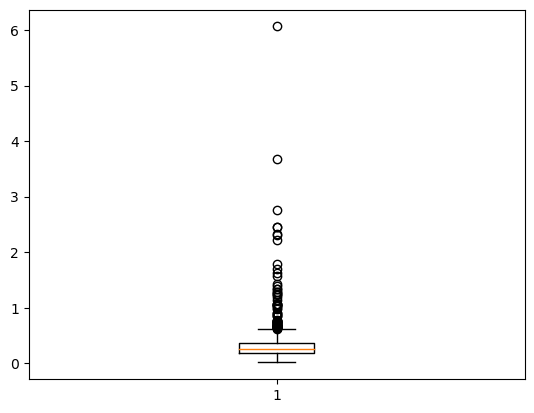

In [88]:
# convert test dataset output to world coordinates
model.load_state_dict(torch.load(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/pointnet_model_cp_detection.pth'))
model.eval()
y_pred = []
y_test = []

for i, data in enumerate(test_loader):
    points, target = data
    points, target = points.to(device), target.to(device)
    outputs = model(points)
    
    y_pred_1 = test_dataset.convert_output(outputs.cpu().detach().numpy(), i) #(3,3)
    y_test_1 = test_dataset.convert_output(target.cpu().detach().numpy(), i)#(3,3)
    
    y_pred.append(y_pred_1)
    y_test.append(y_test_1)

# compute the error
y_pred = np.array(y_pred)
y_test = np.array(y_test)
error = np.linalg.norm(y_pred - y_test, axis=2)
# plot box plot of the error
plt.boxplot(error.flatten())
    

In [74]:
(y_pred - y_test)

array([[-1.8881531 ,  0.7212601 ,  1.741766  , ...,  0.32343102,
         0.8123417 , -1.275239  ],
       [ 1.4982128 , -2.4081268 , -2.645368  , ...,  0.55174637,
         0.35254478,  1.1052456 ],
       [-2.0951538 ,  2.1118526 , -0.96883583, ..., -1.0689049 ,
         1.1558933 ,  0.4133358 ],
       ...,
       [ 0.6035881 ,  0.05761337,  0.3934374 , ...,  0.00379181,
        -0.51747894,  0.75520325],
       [ 0.50632286, -1.5274353 , -0.16441536, ..., -1.4991455 ,
        -0.31300545, -2.2915068 ],
       [ 1.1538811 ,  0.56949234,  0.6545124 , ..., -0.475523  ,
         0.76210594,  1.9895372 ]], dtype=float32)

In [70]:
# convert train dataset into scikit learn dataset and do regression MLP
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

for i in range(len(train_dataset)):
    mesh,y_points = train_dataset[i]
    # y points are the points of 3x3 matrix so flatten it to 9 points
    # if mesh volume is >1440 then skip or < 1100
    m_real = train_data[i]['mesh']
    if i == 0:
        X = mesh.numpy().flatten()
        y = y_points.flatten()
    else:
        X = np.vstack([X, mesh.numpy().flatten()])
        y = np.vstack([y, y_points.flatten()])
#load test dataset

for i in range(len(test_dataset)):
    m_real = test_data[i]['mesh']

    mesh,y_points = test_dataset[i]
    # y points are the points of 3x3 matrix so flatten it to 9 points
    if i == 0:
        X_test = mesh.numpy().flatten()
        y_test = y_points.flatten()
    else:
        X_test = np.vstack([X_test, mesh.numpy().flatten()])
        y_test = np.vstack([y_test, y_points.flatten()])


# do regression

model = MLPRegressor(hidden_layer_sizes=(120, 100,80), max_iter=1000, alpha=0.000001,tol=1e-9, solver='adam', random_state=42,verbose=True)
model.fit(X, y)
y_pred = model.predict(X_test)

print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))
print("Mean absolute error: %.2f", mean_absolute_error(y_test, y_pred))






Iteration 1, loss = 0.01117655
Iteration 2, loss = 0.00166735
Iteration 3, loss = 0.00063302
Iteration 4, loss = 0.00032235
Iteration 5, loss = 0.00019247
Iteration 6, loss = 0.00013043
Iteration 7, loss = 0.00009481
Iteration 8, loss = 0.00007280
Iteration 9, loss = 0.00005762
Iteration 10, loss = 0.00004656
Iteration 11, loss = 0.00003829
Iteration 12, loss = 0.00003183
Iteration 13, loss = 0.00002688
Iteration 14, loss = 0.00002286
Iteration 15, loss = 0.00001964
Iteration 16, loss = 0.00001700
Iteration 17, loss = 0.00001481
Iteration 18, loss = 0.00001299
Iteration 19, loss = 0.00001142
Iteration 20, loss = 0.00001010
Iteration 21, loss = 0.00000899
Iteration 22, loss = 0.00000803
Iteration 23, loss = 0.00000721
Iteration 24, loss = 0.00000650
Iteration 25, loss = 0.00000592
Iteration 26, loss = 0.00000548
Iteration 27, loss = 0.00000507
Iteration 28, loss = 0.00000492
Iteration 29, loss = 0.00000491
Iteration 30, loss = 0.00000401
Iteration 31, loss = 0.00000462
Iteration 32, los

In [95]:
y_pred[0],y_test[0], train_dataset.convert_output(y_test[0],0), train_dataset.convert_output(y_pred[0],0)

(array([0.8670812 , 0.7224261 , 0.37481672, 0.06665014, 0.47885537,
        0.41190016, 0.5063311 , 0.71723515, 0.66102934], dtype=float32),
 array([0.87562773, 0.6915266 , 0.37799711, 0.06762549, 0.47055071,
        0.40905503, 0.50471147, 0.7043577 , 0.66666607]),
 array([[26.8501329 , 22.00349136,  8.77456003],
        [16.84966414, 19.14685135,  9.49193955],
        [22.25938266, 22.16936385, 15.44226924]]),
 array([[26.74435463, 22.40294125,  8.70109891],
        [16.83759255, 19.25420884,  9.55765667],
        [22.27942831, 22.33583561, 15.3120713 ]]))

Iteration 1, loss = 0.03653036
Iteration 2, loss = 0.00333823
Iteration 3, loss = 0.00148666
Iteration 4, loss = 0.00111943
Iteration 5, loss = 0.00099935
Iteration 6, loss = 0.00091021
Iteration 7, loss = 0.00082953
Iteration 8, loss = 0.00074453
Iteration 9, loss = 0.00065745
Iteration 10, loss = 0.00056713
Iteration 11, loss = 0.00050088
Iteration 12, loss = 0.00043447
Iteration 13, loss = 0.00038592
Iteration 14, loss = 0.00033801
Iteration 15, loss = 0.00030715
Iteration 16, loss = 0.00028407
Iteration 17, loss = 0.00026278
Iteration 18, loss = 0.00024511
Iteration 19, loss = 0.00023374
Iteration 20, loss = 0.00021517
Iteration 21, loss = 0.00020608
Iteration 22, loss = 0.00019776
Iteration 23, loss = 0.00019327
Iteration 24, loss = 0.00018390
Iteration 25, loss = 0.00017759
Iteration 26, loss = 0.00016879
Iteration 27, loss = 0.00016391
Iteration 28, loss = 0.00015311
Iteration 29, loss = 0.00014772
Iteration 30, loss = 0.00014600
Iteration 31, loss = 0.00013927
Iteration 32, los

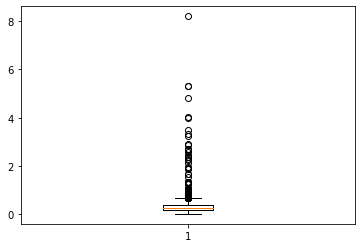

Mean error: 0.31698995580996847
Unnamed: 0                            Ube3a_M_E64-G1817
GENDER                                             male
STRAIN                                      Ube3adelMAT
COHORT_ID                                          c208
DATE                                2021-09-27 00:00:00
CraniumLength                                     26.06
SkullShape                                       normal
Comment                                             NaN
proc_dist                                   1145.686328
abn_distance                                   abnormal
area99perc                                     0.129799
abn_perc                                       abnormal
s_x                                            1.124179
s_y                                            1.032605
s_z                                            0.986688
Specimen_ID                                   E64-G1817
SPECIMEN_ID                                   E64-G1817
VALUE_IMAGE_URI 

In [132]:
# do regression

model = MLPRegressor(hidden_layer_sizes=(100, 100,100), max_iter=1000, alpha=0.00001,tol=1e-8, solver='adam', random_state=42,verbose=True)
model.fit(X, y)
y_pred = model.predict(X_test)

print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))
print("Mean absolute error: %.2f", mean_absolute_error(y_test, y_pred))



# do randomforest regression
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X, y)
y_pred = model.predict(X_test)
print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))

# convert the output to world coordinates and compute the error
y_pred1 = np.reshape(y_pred, (-1, 3, 3))
y_test1 = np.reshape(y_test, (-1, 3, 3))
for i in range(y_pred.shape[0]):
    y_pred1[i] = test_dataset.convert_output(y_pred[i], i)
    y_test1[i] = test_dataset.convert_output(y_test[i], i)

# compute the error
error = np.linalg.norm(y_pred1 - y_test1, axis=2)
# plot box plot of the error
plt.boxplot(error.flatten())
plt.show()

error = np.mean(error, axis=1)
print("Mean error:", np.mean(error))

# print subjects id with the highest error
print(test_df.iloc[np.argmax(error)])
# print highest error
print(np.max(error))


In [94]:
test_df.iloc[0]

Unnamed: 0                                         Tppp3_M_E64-G4728
GENDER                                                          male
STRAIN                                                         Tppp3
COHORT_ID                                                       c228
DATE                                             2022-03-02 00:00:00
CraniumLength                                                  27.33
SkullShape                                                  abnormal
Comment            tendon ossification, cranial sutures open, ros...
proc_dist                                                 672.732342
abn_distance                                                  normal
area99perc                                                  0.019081
abn_perc                                                      normal
s_x                                                          1.01196
s_y                                                         0.997998
s_z                               

In [110]:
# do regression

model = MLPRegressor(hidden_layer_sizes=(100, 100), max_iter=1000, alpha=0.00001,tol=1e-8, solver='adam', random_state=42,verbose=True, activation='logistic')
model.fit(X, y)
y_pred = model.predict(X_test)

print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))
print("Mean absolute error: %.2f", mean_absolute_error(y_test, y_pred))

# do randomforest regression
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X, y)
y_pred = model.predict(X_test)
print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))

# convert the output to world coordinates and compute the error
y_pred = np.reshape(y_pred, (-1, 3, 3))
y_test = np.reshape(y_test, (-1, 3, 3))
for i in range(y_pred.shape[0]):
    y_pred[i] = test_dataset.convert_output(y_pred[i], i)
    y_test[i] = test_dataset.convert_output(y_test[i], i)

# compute the error
error = np.linalg.norm(y_pred - y_test, axis=2)
# plot box plot of the error
plt.boxplot(error.flatten())
plt.show()

error = np.mean(error, axis=1)
print("Mean error:", np.mean(error))

# print subjects id with the highest error
print(test_df.iloc[np.argmax(error)])
# print highest error
print(np.max(error))


Iteration 1, loss = 0.05373441
Iteration 2, loss = 0.00449832
Iteration 3, loss = 0.00176137
Iteration 4, loss = 0.00131550
Iteration 5, loss = 0.00121859
Iteration 6, loss = 0.00115138
Iteration 7, loss = 0.00108942
Iteration 8, loss = 0.00102550
Iteration 9, loss = 0.00095399
Iteration 10, loss = 0.00087887
Iteration 11, loss = 0.00081093
Iteration 12, loss = 0.00074447
Iteration 13, loss = 0.00067585
Iteration 14, loss = 0.00059781
Iteration 15, loss = 0.00053223
Iteration 16, loss = 0.00046982
Iteration 17, loss = 0.00042755
Iteration 18, loss = 0.00039260
Iteration 19, loss = 0.00035355
Iteration 20, loss = 0.00032617
Iteration 21, loss = 0.00030674
Iteration 22, loss = 0.00028868
Iteration 23, loss = 0.00027133
Iteration 24, loss = 0.00025820
Iteration 25, loss = 0.00024515
Iteration 26, loss = 0.00023703
Iteration 27, loss = 0.00022506
Iteration 28, loss = 0.00022098
Iteration 29, loss = 0.00021414
Iteration 30, loss = 0.00019975
Iteration 31, loss = 0.00019286
Iteration 32, los

ValueError: Found array with dim 3. None expected <= 2.

In [99]:
y_pred[0],y_test[0]

(array([[25.310884 , 22.468184 ,  8.718817 ],
        [15.256187 , 19.718822 ,  9.4388075],
        [20.826128 , 22.748793 , 15.279955 ]], dtype=float32),
 array([[25.32801702, 22.38123064,  8.64350353],
        [15.24276541, 19.47399955,  9.351775  ],
        [20.69834691, 22.55004072, 15.22655766]]))

In [98]:
np.linalg.norm(y_pred - y_test, axis=2)

array([[0.1163031 , 0.26017892, 0.24224286],
       [0.12765318, 0.17820763, 0.18607268],
       [0.3543415 , 0.32843698, 0.28861701],
       ...,
       [0.12140997, 0.22666663, 0.0966455 ],
       [0.21359079, 0.1863612 , 0.33500387],
       [0.10423978, 0.19978223, 0.19364496]])

In [133]:
error = np.linalg.norm(y_pred - y_test, axis=2)
# plot box plot of the error
plt.boxplot(error.flatten())
plt.show()

error = np.mean(error, axis=1)
print("Mean error:", np.mean(error))

AxisError: axis 2 is out of bounds for array of dimension 2

In [103]:
print(test_df.iloc[np.argmax(error)])

Unnamed: 0                            Ube3a_M_E64-G1817
GENDER                                             male
STRAIN                                      Ube3adelMAT
COHORT_ID                                          c208
DATE                                2021-09-27 00:00:00
CraniumLength                                     26.06
SkullShape                                       normal
Comment                                             NaN
proc_dist                                   1145.686328
abn_distance                                   abnormal
area99perc                                     0.129799
abn_perc                                       abnormal
s_x                                            1.124179
s_y                                            1.032605
s_z                                            0.986688
Specimen_ID                                   E64-G1817
SPECIMEN_ID                                   E64-G1817
VALUE_IMAGE_URI    2021-11-16/ube3a_m_e64-g1817_

In [105]:
print(np.argmax(error))

558


In [108]:
test_dataset[558]

(tensor([ 0.8280,  0.9978,  0.0710,  0.2743,  0.0394,  0.3838,  0.5513,  0.4917,
          0.3738, -0.0450,  0.2869,  0.5216,  0.1906,  0.6606,  0.4069,  0.5057,
          0.5596,  0.4606,  0.4398,  0.5840,  0.3642,  0.6278,  0.7268,  0.1904,
          0.4724,  0.4401,  0.3818,  0.1711,  0.6526,  0.4971,  0.1741,  0.9768,
          0.2092,  0.4408,  0.7351,  0.8587,  0.4599,  0.6955,  0.0427,  0.4601,
          0.3115,  0.2431,  0.3127,  0.7660,  0.2755,  0.2743,  0.8082,  0.2781,
          0.8515,  0.6811,  0.3871,  0.1346,  0.6586,  0.3774,  0.9094,  0.0985]),
 array([[0.65249887, 0.38140063, 0.65380415],
        [0.40433389, 0.46520142, 0.60951571],
        [0.52725756, 0.47214862, 0.78049326]]))

In [109]:
y_pred[558],y_test[558]

(array([[26.495735, 24.171   , 24.973892],
        [14.316176, 21.796558, 27.369963],
        [22.838068, 24.599277, 34.247437]], dtype=float32),
 array([[28.15401698, 17.80362662, 26.96703111],
        [18.54990437, 21.06898847, 25.13902915],
        [23.30711389, 21.33969168, 32.19611559]]))

In [119]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X, y)
y_pred = model.predict(X_test)
print("Mean squared error: %.2f", mean_squared_error(y_test, y_pred))


Mean squared error: %.2f 321.7769755533437


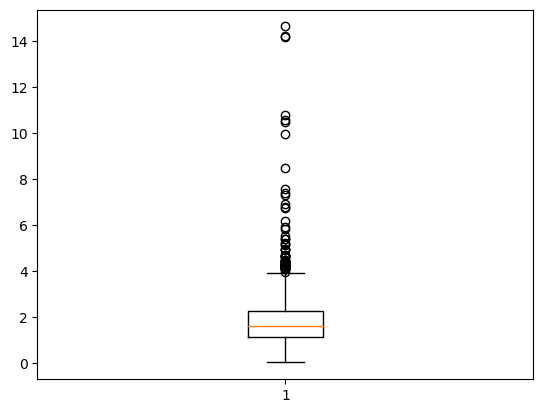

Mean error: 1.7815485
X_test (err> 1) [[-0.061059   -0.1332882  -0.27518034 ...  0.10141364  0.06360658
  -0.13473786]
 [ 0.01988054 -0.15581907 -0.27891093 ... -0.01378849 -0.03236595
   0.27943388]
 [ 0.00376355 -0.08976942 -0.28149047 ...  0.15014161  0.1183171
  -0.08344954]
 ...
 [-0.05257281 -0.14202365 -0.2708576  ...  0.02725191 -0.13238962
   0.1943278 ]
 [-0.05182907 -0.21606667 -0.27544415 ... -0.01647195  0.16720437
  -0.07461578]
 [ 0.00097395 -0.14351825 -0.2759901  ...  0.09630814  0.08079746
  -0.2129013 ]]


In [71]:
y_pred1 = np.reshape(y_pred, (-1, 3, 3))
y_test1 = np.reshape(y_test, (-1, 3, 3))
for i in range(y_pred.shape[0]):
    y_pred1[i] = test_dataset.convert_output(y_pred1[i], i)
    y_test1[i] = test_dataset.convert_output(y_test1[i], i)

# compute the error
error = np.linalg.norm(y_pred1 - y_test1, axis=2)
# plot box plot of the error
plt.boxplot(error.flatten())
plt.show()

error = np.mean(error, axis=1)
print("Mean error:", np.mean(error))
print("X_test (err> 1)", X_test[np.where(error > 1)[0]])

In [179]:
xt = X_test[np.where(error > 1)[0]]
yt = y_test[np.where(error > 1)[0]]
y_p1 = y_pred1[np.where(error > 1)[0]]
y_t1 = y_test1[np.where(error > 1)[0]]
y_p1


array([[[27.318535 , 21.244226 , 16.73314  ],
        [15.857388 , 19.660107 , 16.618988 ],
        [22.569185 , 21.935621 , 22.676472 ]],

       [[26.849527 , 18.197002 ,  7.9192224],
        [15.803685 , 16.855633 ,  7.7794256],
        [21.426523 , 19.080025 , 12.815905 ]]], dtype=float32)

In [178]:
test_df.iloc[np.where(error > 1)[0]]

,Unnamed: 0,GENDER,STRAIN,COHORT_ID,DATE,CraniumLength,SkullShape,Comment,proc_dist,abn_distance,area99perc,abn_perc,s_x,s_y,s_z,Specimen_ID,SPECIMEN_ID,VALUE_IMAGE_URI
2949,Impact_F_E64-G9146,female,Impact,c262,2022-10-31,25.87,normal,NaN,600.135605,normal,0.008224,normal,1.002021,0.950779,0.937110,E64-G9146,E64-G9146,2022-12-08/impact_f_e64-g9146_cr1.bmp
3396,Xrcc5_F_E64-CC060,female,Xrcc5,c270,2022-12-27,21.55,abnormal,"tail tip deformed, kyphosis severe, cranial su...",1992.460644,abnormal,0.617021,abnormal,0.906921,0.831809,0.785029,E64-CC060,E64-CC060,2023-01-10/xrcc5_f_e64-cc060_cr1.bmp


In [145]:
y_t1

array([[[19.85693909, 16.45834042,  7.87790139],
        [10.44192828, 14.37124379,  7.0997865 ],
        [15.50801664, 13.56981988, 13.36891247]],

       [[25.87758211, 21.46439814, 11.87875896],
        [16.00192792, 18.81937656, 11.88213739],
        [20.70590759, 21.5826832 , 17.94884928]],

       [[25.5217304 , 23.83183444, 16.30110223],
        [16.63076604, 18.97570834, 17.44960284],
        [21.61032239, 22.9531983 , 22.9684108 ]],

       [[26.79031913, 22.62550308, 18.33724087],
        [17.01596416, 20.95342746, 19.03843699],
        [22.41128452, 23.01983037, 24.73685943]],

       [[26.38741985, 21.62207419,  9.49723936],
        [15.90758752, 21.08239095,  9.02516667],
        [21.22468843, 22.97049567, 15.49047226]],

       [[27.03958804, 22.71446214, 18.72023619],
        [16.88811281, 20.9162524 , 19.17721633],
        [22.29254112, 23.00257419, 25.00845943]],

       [[26.03803178, 21.52698902, 16.69925695],
        [16.14266729, 19.48129873, 17.00510331],
        

In [163]:
test_dataset[46]

(tensor([0.2703, 0.1243, 0.6796, 0.2506, 0.5642, 0.5037, 0.5864, 0.3988, 0.5251,
         0.1519, 0.1038, 0.8006, 0.4033, 0.2274, 0.7938, 0.4149, 0.4117, 0.3995,
         0.4695, 0.4316, 0.2710, 0.5525, 0.3501, 0.3060, 0.4047, 0.6944, 0.4203,
         0.5003, 0.3732, 0.5598, 0.4242, 0.2799, 0.5722, 0.3423, 0.0724, 0.2737,
         0.6974, 0.7638, 0.5626, 0.4198, 0.2110, 0.5458, 0.2702, 0.3825, 0.5162,
         0.3860, 0.3006, 0.2307, 0.3683, 0.5137, 0.2630, 0.5211, 0.3274, 0.1629,
         0.6381, 0.5450]),
 array([[0.56546226, 0.80537342, 0.46410684],
        [0.04976812, 0.66648952, 0.46423966],
        [0.29540397, 0.81158429, 0.70275025]]))

In [149]:
pts_w = get_points_from_mesh("/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230313c281_Faim2 & Gnl2 & Klhl6 & Mrvi1 & wt/skull_shape_workdir/Faim2_M_E64-CD092/head_affine_registered.obj")

In [150]:
apply_transform_pts("/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20230313c281_Faim2 & Gnl2 & Klhl6 & Mrvi1 & wt/skull_shape_workdir/Faim2_M_E64-CD092/affine_head.mat", pts_w)

array([[-26.55344833, -22.10940011,   9.56942155],
       [-16.19880174, -21.8719833 ,   9.14946135],
       [-21.46327062, -23.04832691,  15.74192537]])

In [162]:
np.where(error > 1)[0]

array([ 46,  57, 183, 306, 388, 459, 539, 558, 564, 568, 616, 618, 672,
       709, 719])

In [153]:
read_subject( "Faim2_M_E64-CD092","c281" )

(<vtkmodules.vtkCommonDataModel.vtkPolyData(0x4cf60ec0) at 0x7fa7fc1038e0>,
 array([[-26.55344833, -22.10940011,   9.56942155],
        [-16.19880174, -21.8719833 ,   9.14946135],
        [-21.46327062, -23.04832691,  15.74192537]]))

In [154]:
test_data[27]

{'points': array([[-19.85693909, -16.45834042,   7.87790139],
        [-10.44192828, -14.37124379,   7.0997865 ],
        [-15.50801664, -13.56981988,  13.36891247]]),
 'mesh': <vtkmodules.vtkCommonDataModel.vtkPolyData(0x243be350) at 0x7fa802324be0>}

In [181]:

for id3 in np.where(error > 0.5)[0].tolist():
    tmp = read_subject(test_df.iloc[id3]['Unnamed: 0'], test_df.iloc[id3]['COHORT_ID'])
    test_data[id3] = {"points": tmp[1], "mesh": tmp[0]}

100%|██████████| 3141/3141 [00:02<00:00, 1328.60it/s]


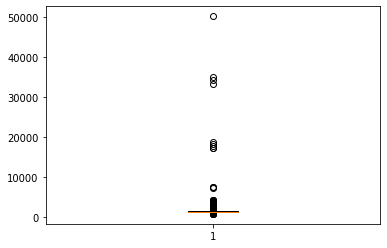

50% quantile 1326.5839166732815
5% quantile 1181.5850393183491
95% quantile 1438.506330357737
Mean volume 1423.2865368042776


100%|██████████| 781/781 [00:00<00:00, 1345.91it/s]


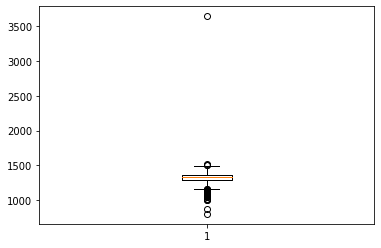

50% quantile 1326.8222653131934
5% quantile 1163.865717339139
95% quantile 1430.6576154794614
Mean volume 1319.991731506139


In [184]:

for data in [train_data, test_data]:
    volumes = []
    for i in tqdm(range(len(data))):
        mesh = data[i]['mesh']
        volumes.append(compute_volume(mesh))
    plt.boxplot(volumes)
    plt.show()
    # compute 50% quantile 5% quantile and 95% quantile
    print("50% quantile", np.quantile(volumes, 0.5))
    print("5% quantile", np.quantile(volumes, 0.05))
    print("95% quantile", np.quantile(volumes, 0.95))
    print("Mean volume", np.mean(volumes))
    
    

In [ ]:
# save pca and model to a file
import pickle
with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/point_detector_model.pkl', 'wb') as f:
    pickle.dump(pipeline, f)
    pickle.dump(model, f)

# load the model
with open(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/point_detector_model.pkl', 'rb') as f:
    pipeline = pickle.load(f)
    model = pickle.load(f)


In [67]:
X_test

array([[-0.061059  , -0.1332882 , -0.27518034],
       [ 0.05322262, -0.03277547,  0.33891115],
       [ 0.06974529,  0.14071223, -0.01907938],
       ...,
       [-0.00883985,  0.0611698 ,  0.18525907],
       [ 0.08789629, -0.06640973,  0.05627753],
       [ 0.09630814,  0.08079746, -0.2129013 ]], dtype=float32)